
# Task 2: Time-Series Regression (Remaining Useful Life/RUL)

## 1. Project Overview

### 1.1 Problem Definition

This project focuses on predicting the **Remaining Useful Life (RUL)** of press machines using time‑series sensor measurements collected throughout operational cycles. 

The primary objective is to estimate the number of remaining operating cycles before machine failure occurs, enabling valuable information for maintenance scheduling and reliability management. 

To improve model practicality and stability, the target variable is capped at a **maximum value of one hundred fifty operating cycles**.

$$
RUL_t = \min(T_{\text{failure}} - t, 150)$$

### 1.2 Project Objectives

1. Perform Exploratory Data Analysis (EDA).
2. Conduct data preprocessing and RUL label generation.
3. Transform time-series data into sliding windows.
4. Develop and compare sequence-based Deep Learning models.
5. Establish a non-Deep Learning baseline.
6. Perform machine-level validation.
7. Estimate prediction uncertainty.
8. Evaluate models using RMSE and Asymmetric Score.

### 1.3 Evaluation Metrics

- Root Mean Squared Error (RMSE)
- Asymmetric Score

### 1.4 Project Requirements

- At least two sequence-based Deep Learning architectures.
- One non-Deep Learning baseline.
- Machine-level train-validation split.
- Prediction intervals using Monte Carlo Dropout or Ensemble.
- Final RUL prediction for test machines.



## 2. Library Imports

Several Python libraries are imported to facilitate data processing, file operations, archive handling, and formatted output generation, forming the foundation for subsequent project implementations:

- **Pandas:** Used for data manipulation and tabular data analysis.
- **Pathlib:** Used to manage file and directory paths.
- **IPython.display:** Provides functions to display formatted outputs and render Markdown content within the notebook.
- **ZipFile:** Used to access and read files directly from a ZIP archive without manually extracting its contents.

Additional libraries will be imported in subsequent sections depending on the requirements of data analysis, preprocessing, visualization, and model development.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
from zipfile import ZipFile
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

## 3. Dataset Understanding

### 3.1 Dataset Archive Inventory

The following code inspects the compressed dataset archive and builds a formatted summary table displaying each file name along with its corresponding storage size in megabytes.

In [18]:
zip_path = Path(r"C:\Users\LENOVO\OneDrive\Documents\Telkom University\SEMESTER 9\Deep Learning\UTS\data_uts_dl.zip")

if zip_path.exists():
    with ZipFile(zip_path, "r") as zip_ref: #r means read, zip_ref is for the zip folder that opened
        files = [item for item in zip_ref.infolist() if not item.is_dir()] #infolist takes zip lists, dir represent if the item a file not a dictionary
        inventory = pd.DataFrame([{
        "No": idx + 1,
        "File Name": file.filename,
        "File Size (MB)": file.file_size / (1024 * 1024) #byte to mb
        } for idx, file in enumerate(files)])

    display(
        inventory.style
        .set_caption("Dataset Inventory")
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("text-align", "center"),
                    ("font-size", "14px"),
                    ("font-weight", "bold"),
                    ("caption-side", "top"),
                    ("padding-bottom", "8px")
                ]},
            {"selector": "th", "props": [("text-align", "center")]}
        ])
        .format({"File Size (MB)": "{:.2f}"})
        .set_properties(**{"text-align": "center"})
        .set_properties(subset=["File Name"], **{"text-align": "left"})
        .hide(axis="index")
    )

else: 
    print("Archive data_uts_dl.zip not found at local path. Proceeding with data/ folder.")

No,File Name,File Size (MB)
1,klasifikasi_train_meta.csv,1.73
2,klasifikasi_test.npz,58.27
3,kamus_data.md,0.00
4,klasifikasi_train.npz,170.99
5,rul_test.csv.gz,3.94
6,rul_train.csv.gz,19.40
7,clustering_meta.csv,0.57
8,klasifikasi_test_meta.csv,0.46
9,clustering.npz,124.22


### 3.2 Data Dictionary Inspection

The following code extracts and renders the official data dictionary from the archive so that all variable definitions and target labeling rules remain clearly documented in the notebook.

In [19]:
kamusData = (Path.cwd().parent if Path.cwd().name.lower() == "kode" else Path.cwd()) / "kamus_data.md"

if zip_path.exists():
    with ZipFile(zip_path, "r") as zip_ref:
        kamus_data = next(
            name for name in zip_ref.namelist()
            if name.lower().endswith("kamus_data.md")
        )
        kamus_text = zip_ref.read(kamus_data).decode("utf-8-sig", errors="replace")
    display(Markdown(kamus_text))
elif kamusData.exists():
    display(Markdown(kamusData.read_text(encoding="utf-8")))
else:
    print("kamus_data.md not found locally.")

# Kamus data UTS Deep Learning

Semua kelompok menerima data yang sama. Label data uji tidak dibagikan.

## Tugas 1: klasifikasi_train.npz, klasifikasi_test.npz, klasifikasi_*_meta.csv

Satu sampel per unit produk dari pabrik komponen fiktif. Baris ke-i di berkas meta
memakai `indeks` = i pada array di berkas npz.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), foto permukaan produk |
| `sensor` | Array float16 (N, 3, 128): suhu (C), getaran (relatif), arus (A) selama penekanan. NaN berarti data tidak terekam |
| id_unit | ID unit produk |
| lini | Lini produksi (A atau B) |
| shift | Shift produksi |
| id_mesin | Mesin penekan |
| batch_material | Batch bahan baku |
| kelas | Label: normal, gores, noda, retak, gelembung, las_dingin, kontaminasi. Hanya di data latih |

Label data latih berasal dari inspektur dan tidak dijamin bebas salah.

## Tugas 2: rul_train.csv.gz dan rul_test.csv.gz

Log per siklus untuk mesin press fiktif. Data latih berisi riwayat sampai mesin rusak.
Data uji berhenti pada titik acak sebelum rusak.

| Kolom | Keterangan |
| --- | --- |
| id_unit | ID mesin |
| siklus | Nomor siklus sejak mesin mulai dipakai |
| setel_1, setel_2, setel_3 | Pengaturan operasi pada siklus itu |
| s01-s21 | Bacaan sensor. NaN berarti bacaan hilang |

Label: sisa umur pakai (RUL) = jumlah siklus tersisa sampai rusak, dipotong pada 150
(sisa umur di atas 150 siklus dihitung 150). Di data latih, siklus terakhir tiap unit adalah
siklus saat rusak, jadi labelnya dihitung sendiri. Prediksi RUL dibuat pada siklus terakhir
tiap unit di data uji.

## Tugas 3: clustering.npz dan clustering_meta.csv

Sampel material dari laboratorium fiktif, tanpa label.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), citra mikrostruktur dari mikroskop |
| `spektrum` | Array float16 (N, 128), spektrum komposisi |
| id_sampel | ID sampel |
| mikroskop | Mikroskop yang dipakai (M1 atau M2) |


### 3.3 Loading and Initial Dataset Verification

The RUL training and testing datasets are loaded into Pandas DataFrames. Their dimensions, column structures, and machine identifiers are examined to ensure data integrity before proceeding to exploratory data analysis.

In [20]:
project_dir = Path.cwd()
if project_dir.name.lower() == "kode":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True) #data dictionary

with ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()
    train_file = next(name for name in files if name.lower().endswith("rul_train.csv.gz"))
    test_file = next(name for name in files if name.lower().endswith("rul_test.csv.gz"))

    train_path = data_dir / "rul_train.csv.gz"
    test_path = data_dir / "rul_test.csv.gz"

    train_path.write_bytes(zip_ref.read(train_file))
    test_path.write_bytes(zip_ref.read(test_file))

train = pd.read_csv(train_path, compression="gzip")
test = pd.read_csv(test_path, compression="gzip")

print(f"Training shape    : {train.shape}")
print(f"Testing shape     : {test.shape}")
print(f"Training machines : {train['id_unit'].nunique()}")
print(f"Testing machines  : {test['id_unit'].nunique()}")

expected_columns = ["id_unit", "siklus", "setel_1", "setel_2", "setel_3"] + [f"s{i:02d}" for i in range(1, 22)]
print("Missing train cols:", [c for c in expected_columns if c not in train.columns])
print("Missing test cols :", [c for c in expected_columns if c not in test.columns])

display(
    train.head(3).style
    .set_caption("Table 3.1 Sample Records of RUL Training Dataset")
    .set_table_styles([
        {"selector": "caption", "props": [("text-align", "center"), ("font-weight", "bold"), ("caption-side", "top")]},
        {"selector": "th", "props": [("text-align", "center")]}
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

Training shape    : (254174, 26)
Testing shape     : (51692, 26)
Training machines : 900
Testing machines  : 300
Missing train cols: []
Missing test cols : []


id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
3,1,20.001000,0.700500,100.000000,1107.746000,569.289000,991.700000,1099.533000,nan,1313.240000,725.325000,778.517000,499.195000,782.886000,1495.906000,1092.248000,1144.779000,1345.634000,873.087000,851.099000,408.142000,997.673000,838.331000,1012.076000,439.003000
3,2,34.996000,0.842400,100.000000,1071.040000,587.821000,1013.673000,nan,157.684000,1304.796000,729.707000,776.236000,452.236000,819.193000,1492.101000,1095.511000,1167.320000,1340.661000,871.230000,791.396000,398.338000,980.601000,814.985000,1108.741000,412.368000
3,3,0.001000,-0.001200,100.000000,1130.132000,585.094000,998.221000,1127.436000,161.918000,1314.296000,725.847000,783.364000,533.958000,829.940000,1505.026000,1091.245000,1170.340000,1330.785000,872.114000,807.389000,388.304000,938.802000,847.512000,1003.616000,455.443000


## 4. Exploratory Data Analysis (EDA)

### 4.1 Machine Identification and Operating Cycle Analysis

This section examines machine counts, identifier ranges, and operating cycle distributions across training and testing datasets while clarifying the distinct roles of `id_unit` and `siklus` variables.

In [21]:
setting_cols = ["setel_1", "setel_2", "setel_3"]
sensor_cols = [f"s{i:02d}" for i in range(1, 22)]

train_cycle_stats = (
    train.groupby("id_unit")
    .agg(
        jumlah_siklus=("siklus", "count"),
        siklus_min=("siklus", "min"),
        siklus_max=("siklus", "max")
    )
    .reset_index()
)

test_cycle_stats = (
    test.groupby("id_unit")
    .agg(
        jumlah_siklus=("siklus", "count"),
        siklus_min=("siklus", "min"),
        siklus_max=("siklus", "max")
    )
    .reset_index()
)

print("TRAINING DATASET")
print("Unique machines:", train["id_unit"].nunique())
print("Minimum machine ID:", train["id_unit"].min())
print("Maximum machine ID:", train["id_unit"].max())
print("Minimum cycle:", train["siklus"].min())
print("Maximum cycle:", train["siklus"].max())

print("\nTESTING DATASET")
print("Unique machines:", test["id_unit"].nunique())
print("Minimum machine ID:", test["id_unit"].min())
print("Maximum machine ID:", test["id_unit"].max())
print("Minimum cycle:", test["siklus"].min())
print("Maximum cycle:", test["siklus"].max())

print("\nTRAINING CYCLE STATISTICS")
display(train_cycle_stats["jumlah_siklus"].describe().to_frame().T.round(2))

print("\nFirst 10 training machine records")
display(train_cycle_stats.head(10))

column_roles = pd.DataFrame({
    "Column": ["id_unit", "siklus"],
    "Data Type": [
        str(train["id_unit"].dtype),
        str(train["siklus"].dtype)
    ],
    "Unique Values": [
        train["id_unit"].nunique(),
        train["siklus"].nunique()
    ],
    "Role": [
        "Machine identifier",
        "Temporal operating cycle"
    ]
})

display(column_roles)

# Check duplicate machine-cycle records
print(
    "\nDuplicate machine-cycle records:",
    train.duplicated(["id_unit", "siklus"]).sum()
)


TRAINING DATASET
Unique machines: 900
Minimum machine ID: 3
Maximum machine ID: 1199
Minimum cycle: 1
Maximum cycle: 778

TESTING DATASET
Unique machines: 300
Minimum machine ID: 1
Maximum machine ID: 1200
Minimum cycle: 1
Maximum cycle: 455

TRAINING CYCLE STATISTICS


,count,mean,std,min,25%,50%,75%,max
jumlah_siklus,900.0,282.42,84.63,133.0,224.0,265.0,323.0,778.0



First 10 training machine records


,id_unit,jumlah_siklus,siklus_min,siklus_max
0,3,318,1,318
1,4,222,1,222
2,5,600,1,600
3,7,238,1,238
4,9,219,1,219
5,10,237,1,237
6,11,312,1,312
7,12,311,1,311
8,13,199,1,199
9,14,172,1,172


,Column,Data Type,Unique Values,Role
0,id_unit,int64,900,Machine identifier
1,siklus,int64,778,Temporal operating cycle



Duplicate machine-cycle records: 0


### 4.2 Missing Values and Sensor Informativeness

This section evaluates dataset completeness by identifying missing values across all variables while examining sensor variability to detect constant or non‑informative measurements for predictive modeling.

In [22]:
missing_table = pd.DataFrame({
    "Train Missing": train.isna().sum(),
    "Train Missing (%)": train.isna().mean() * 100,
    "Test Missing": test.isna().sum(),
    "Test Missing (%)": test.isna().mean() * 100
})

missing_table = missing_table.sort_values(
    "Train Missing (%)",
    ascending=False
)

print("MISSING VALUES SUMMARY")
display(missing_table.round(2))

unique_count = train[sensor_cols].nunique(dropna=True)
sensor_std = train[sensor_cols].std()

sensor_info = pd.DataFrame({
    "Unique Values": unique_count,
    "Missing Count": train[sensor_cols].isna().sum(),
    "Missing (%)": train[sensor_cols].isna().mean() * 100,
    "Mean": train[sensor_cols].mean(),
    "Std": sensor_std
})

conditions = [
    sensor_info["Unique Values"] == 0,
    sensor_info["Unique Values"] == 1
]

choices = [
    "All values missing",
    "Constant / Non-informative"
]

sensor_info["Status"] = np.select(
    conditions,
    choices,
    default="Informative"
)

informative_sensor_cols = sensor_info.index[
    sensor_info["Status"] == "Informative"
].tolist()

print("\nSENSOR INFORMATIVENESS TABLE")
display(sensor_info.round(3).rename_axis("Sensor").reset_index())

print("\nInformative sensors:", len(informative_sensor_cols))
print("Non-informative sensors:",
      len(sensor_cols) - len(informative_sensor_cols))


MISSING VALUES SUMMARY


,Train Missing,Train Missing (%),Test Missing,Test Missing (%)
s20,5371,2.11,1013,1.96
s02,5272,2.07,1008,1.95
s06,5235,2.06,1044,2.02
s18,5235,2.06,992,1.92
s07,5219,2.05,1035,2.00
s04,5215,2.05,1082,2.09
s12,5193,2.04,976,1.89
s09,5173,2.04,1025,1.98
s13,5162,2.03,1009,1.95
s19,5156,2.03,1053,2.04



SENSOR INFORMATIVENESS TABLE


,Sensor,Unique Values,Missing Count,Missing (%),Mean,Std,Status
0,s01,66416,5081,1.999,1101.646,17.760,Informative
1,s02,49790,5272,2.074,579.598,15.929,Informative
2,s03,73424,5116,2.013,1005.494,23.054,Informative
3,s04,66366,5215,2.052,1133.476,17.625,Informative
4,s05,4860,5109,2.010,168.545,9.489,Informative
5,s06,39558,5235,2.060,1310.545,8.695,Informative
6,s07,33031,5219,2.053,723.626,6.827,Informative
7,s08,33082,5130,2.018,779.354,6.859,Informative
8,s09,39186,5173,2.035,498.012,25.157,Informative
9,s10,34473,5138,2.021,803.320,17.416,Informative



Informative sensors: 21
Non-informative sensors: 0


### 4.3 Operating Settings and Sensor Distribution

This section examines the statistical distributions of
operating settings and sensor measurements using descriptive statistics and visualizations to evaluate variability, spread, and overall distribution patterns.

OPERATING SETTINGS STATISTICS


,count,mean,std,min,25%,50%,75%,max
setel_1,254174.0,22.023,14.210,-0.008,10.00,24.993,35.000,42.008
setel_2,254174.0,0.542,0.313,-0.008,0.25,0.695,0.839,0.849
setel_3,254174.0,93.357,14.886,60.000,100.00,100.000,100.000,100.000



SENSOR READINGS STATISTICS


,count,mean,std,min,25%,50%,75%,max
s01,249093.0,1101.646,17.760,1042.699,1089.314,1100.198,1115.557,1161.239
s02,248902.0,579.598,15.929,537.791,569.502,580.095,586.165,619.762
s03,249058.0,1005.494,23.054,943.024,988.301,999.592,1017.862,1081.733
s04,248959.0,1133.476,17.625,1079.085,1124.402,1133.505,1145.767,1196.050
s05,249065.0,168.545,9.489,156.897,161.767,162.578,173.896,187.159
s06,248939.0,1310.545,8.695,1267.150,1304.219,1309.544,1315.358,1358.938
s07,248955.0,723.626,6.827,683.143,719.193,723.476,728.895,754.713
s08,249044.0,779.354,6.859,750.189,775.063,780.140,784.097,810.489
s09,249001.0,498.012,25.157,444.323,489.275,497.380,515.702,543.874
s10,249036.0,803.320,17.416,771.549,783.859,802.902,819.451,839.647


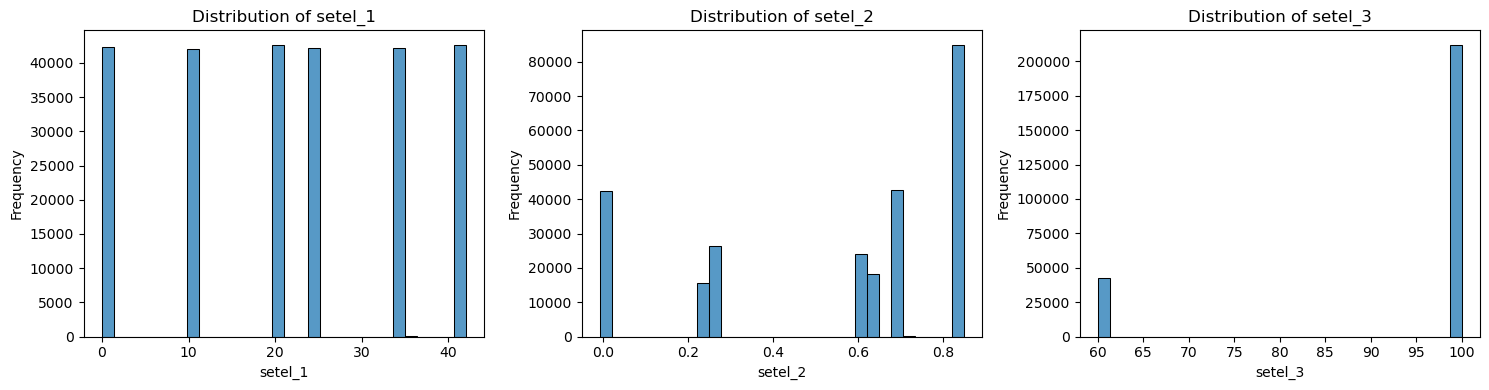

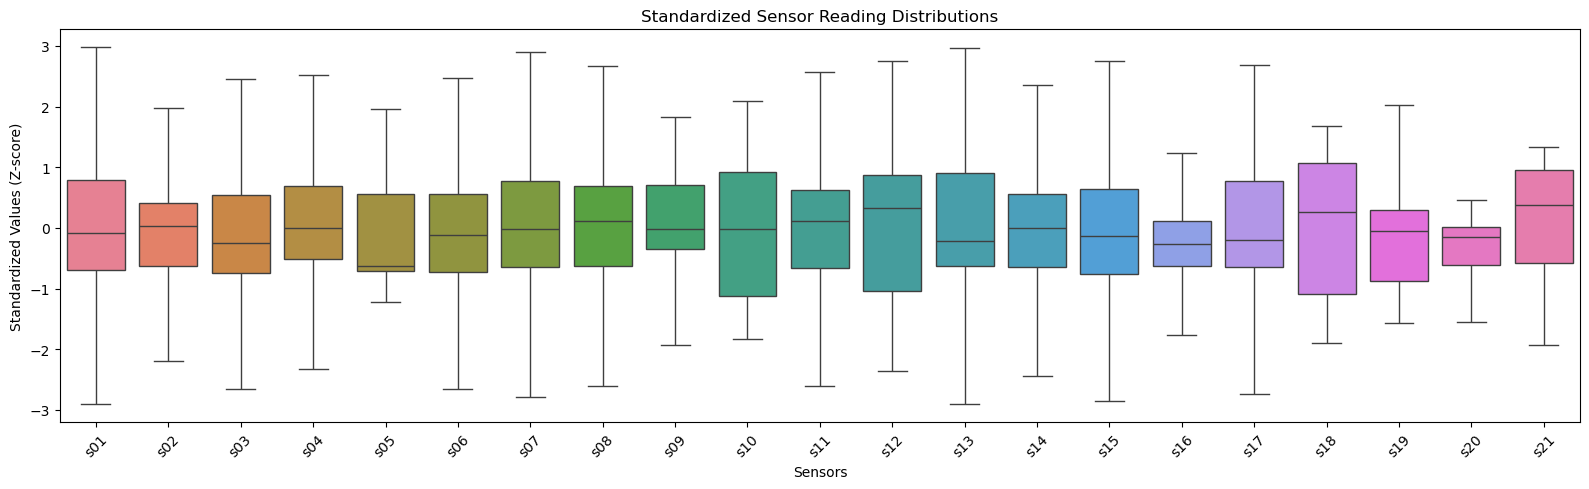

In [23]:
print("OPERATING SETTINGS STATISTICS")
display(train[setting_cols].describe().T.round(3))

print("\nSENSOR READINGS STATISTICS")
display(train[sensor_cols].describe().T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, setting_cols):
    sns.histplot(
        data=train,
        x=col,
        bins=30,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

valid_sensor_cols = sensor_info.index[
    sensor_info["Std"].fillna(0) > 0
].tolist()

if valid_sensor_cols:
    sensor_zscore = (
        train[valid_sensor_cols] -
        train[valid_sensor_cols].mean()
    ) / train[valid_sensor_cols].std()

    plt.figure(figsize=(16, 5))

    sns.boxplot(
        data=sensor_zscore,
        showfliers=False
    )

    plt.title("Standardized Sensor Reading Distributions")
    plt.xlabel("Sensors")
    plt.ylabel("Standardized Values (Z-score)")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

### 4.4 Operating Settings Relationships and Outlier Detection

This section investigates relationships between operating settings and sensor measurements through correlation analysis while identifying potential outliers using the Interquartile Range (IQR) method and time‑series visualization.

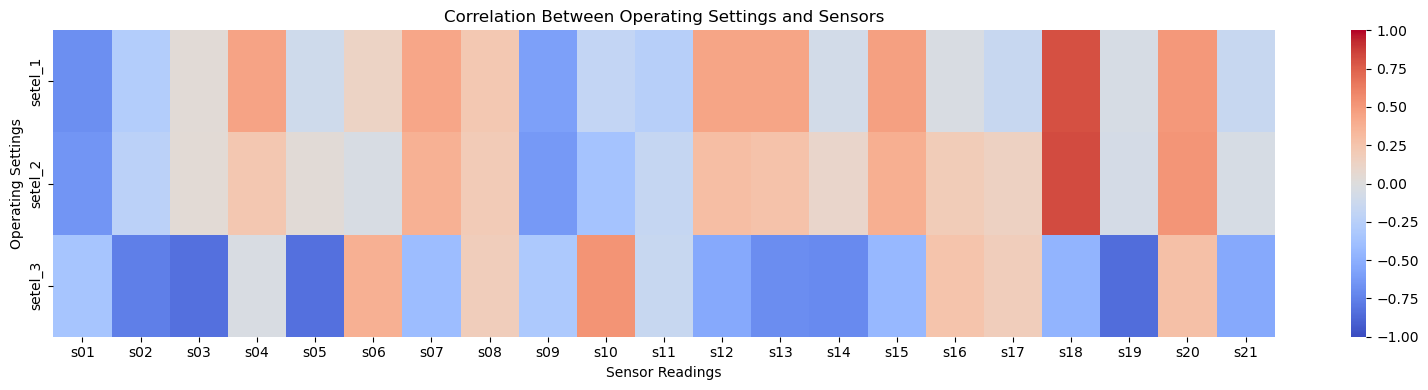

POTENTIAL SENSOR OUTLIERS


,Outlier Count,Valid Values,Outlier (%)
s01,33,249093,0.013
s02,946,248902,0.380
s03,128,249058,0.051
s04,350,248959,0.141
s05,0,249065,0.000
s06,2064,248939,0.829
s07,1656,248955,0.665
s08,888,249044,0.357
s09,231,249001,0.093
s10,0,249036,0.000


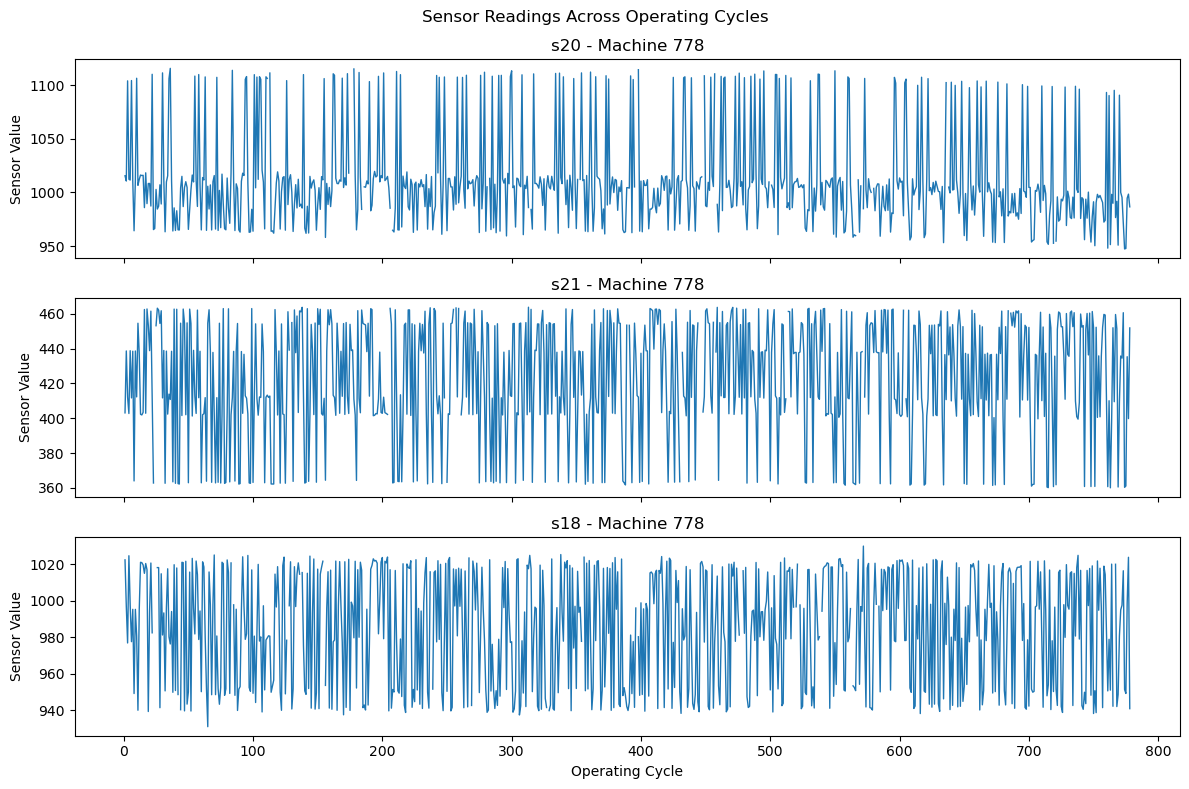

In [24]:
correlation_matrix = train[
    setting_cols + sensor_cols
].corr()

setting_sensor_corr = correlation_matrix.loc[
    setting_cols,
    sensor_cols
]

plt.figure(figsize=(16, 4))

sns.heatmap(
    setting_sensor_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title("Correlation Between Operating Settings and Sensors")
plt.xlabel("Sensor Readings")
plt.ylabel("Operating Settings")
plt.tight_layout()
plt.show()

Q1 = train[sensor_cols].quantile(0.25)
Q3 = train[sensor_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (train[sensor_cols] < lower_bound) |
    (train[sensor_cols] > upper_bound)
)

valid_counts = train[sensor_cols].count()

outlier_table = pd.DataFrame({
    "Outlier Count": outlier_mask.sum(),
    "Valid Values": valid_counts,
    "Outlier (%)": (
        outlier_mask.sum() / valid_counts * 100
    )
})

print("POTENTIAL SENSOR OUTLIERS")
display(outlier_table.round(3))

sample_unit = train_cycle_stats.loc[
    train_cycle_stats["jumlah_siklus"].idxmax(),
    "id_unit"
]

sample_data = (
    train[train["id_unit"] == sample_unit]
    .sort_values("siklus")
)

top_sensors = (
    sensor_info["Std"]
    .dropna()
    .nlargest(3)
    .index.tolist()
)

fig, axes = plt.subplots(
    len(top_sensors),
    1,
    figsize=(12, 8),
    sharex=True
)

axes = np.atleast_1d(axes)

for ax, sensor in zip(axes, top_sensors):
    ax.plot(
        sample_data["siklus"],
        sample_data[sensor],
        linewidth=1
    )

    ax.set_title(f"{sensor} - Machine {sample_unit}")
    ax.set_ylabel("Sensor Value")

axes[-1].set_xlabel("Operating Cycle")

plt.suptitle("Sensor Readings Across Operating Cycles")
plt.tight_layout()
plt.show()


## 5. Remaining Useful Life (RUL) Label Generation

This section generates Remaining Useful Life (RUL) labels by calculating the difference between failure and current operating cycles, while applying a maximum threshold of 150 cycles.

In [25]:
train_labeled = train.sort_values(
    ["id_unit", "siklus"]
).copy()

failure_cycle = (
    train_labeled.groupby("id_unit")["siklus"]
    .transform("max")
)

train_labeled["rul"] = (
    failure_cycle - train_labeled["siklus"]
).clip(upper=150)

print("RUL label generation completed.")

print("\nTraining dataset shape:", train_labeled.shape)

print("\nRUL range:")
print("Minimum RUL:", train_labeled["rul"].min())
print("Maximum RUL:", train_labeled["rul"].max())

display(
    train_labeled[
        ["id_unit", "siklus", "rul"]
    ].head(10)
)


RUL label generation completed.

Training dataset shape: (254174, 27)

RUL range:
Minimum RUL: 0
Maximum RUL: 150


,id_unit,siklus,rul
0,3,1,150
1,3,2,150
2,3,3,150
3,3,4,150
4,3,5,150
5,3,6,150
6,3,7,150
7,3,8,150
8,3,9,150
9,3,10,150


In [26]:
rul_summary = (
    train_labeled.groupby("id_unit")
    .agg(
        first_cycle=("siklus", "min"),
        failure_cycle=("siklus", "max"),
        total_records=("siklus", "count"),
        initial_rul=("rul", "first"),
        final_rul=("rul", "last")
    )
    .reset_index()
)

print("RUL SUMMARY PER MACHINE")

display(
    rul_summary.head(10).style
    .set_caption("Machine-Level RUL Summary")
    .format({
        "initial_rul": "{:.0f}",
        "final_rul": "{:.0f}"
    })
    .hide(axis="index")
)


RUL SUMMARY PER MACHINE


id_unit,first_cycle,failure_cycle,total_records,initial_rul,final_rul
3,1,318,318,150,0
4,1,222,222,150,0
5,1,600,600,150,0
7,1,238,238,150,0
9,1,219,219,150,0
10,1,237,237,150,0
11,1,312,312,150,0
12,1,311,311,150,0
13,1,199,199,150,0
14,1,172,172,150,0


In [ ]:
assert train_labeled["rul"].between(0, 150).all()
last_records = train_labeled.groupby("id_unit").tail(1)
assert (last_records["rul"] == 0).all()

print("All RUL labels are within the range of 0-150.")
print("All machine failure cycles have RUL = 0.")
print("RUL validation passed.")


All RUL labels are within the range of 0-150.
All machine failure cycles have RUL = 0.
RUL validation passed.


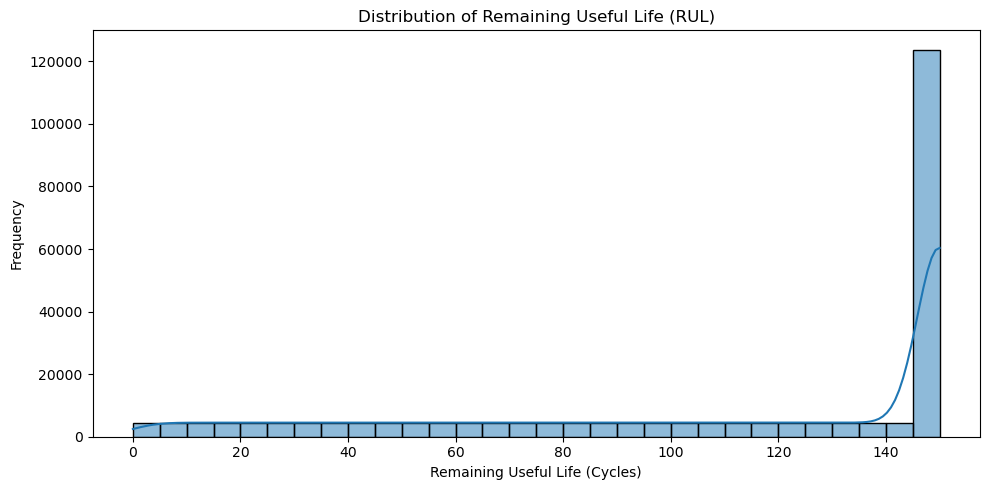

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_labeled,
    x="rul",
    bins=30,
    kde=True
)

plt.title("Distribution of Remaining Useful Life (RUL)")
plt.xlabel("Remaining Useful Life (Cycles)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


## 6. Sliding Window Generation

This section transforms machine operating histories into fixed‑length time‑series sequences using a sliding window approach while preventing data leakage through machine‑based training and validation separation.

In [29]:
setting_cols = ["setel_1", "setel_2", "setel_3"]
sensor_cols = [f"s{i:02d}" for i in range(1, 22)]

feature_cols = setting_cols + sensor_cols

WINDOW_SIZE = 30
WINDOW_STEP = 5

print("Total input features:", len(feature_cols))
print("Window size:", WINDOW_SIZE)
print("Window step:", WINDOW_STEP)

Total input features: 24
Window size: 30
Window step: 5


In [30]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_labeled,
        groups=train_labeled["id_unit"]
    )
)

train_part = train_labeled.iloc[train_idx].copy()
val_part = train_labeled.iloc[val_idx].copy()

train_part = train_part.sort_values(
    ["id_unit", "siklus"]
)

val_part = val_part.sort_values(
    ["id_unit", "siklus"]
)

train_machine_ids = set(train_part["id_unit"].unique())
val_machine_ids = set(val_part["id_unit"].unique())

assert train_machine_ids.isdisjoint(val_machine_ids)

print("Training machines:", len(train_machine_ids))
print("Validation machines:", len(val_machine_ids))
print("Machine overlap:", len(train_machine_ids & val_machine_ids))


Training machines: 720
Validation machines: 180
Machine overlap: 0


In [31]:
train_part = train_part.sort_values(["id_unit", "siklus"])
val_part = val_part.sort_values(["id_unit", "siklus"])
test_part = test.sort_values(["id_unit", "siklus"]).copy()

train_part[feature_cols] = (
    train_part.groupby("id_unit")[feature_cols].ffill()
)

feature_medians = train_part[feature_cols].median().fillna(0)

def impute_features(df):
    df = df.copy()

    df[feature_cols] = (
        df.groupby("id_unit")[feature_cols].ffill()
    )

    df[feature_cols] = df[feature_cols].fillna(feature_medians)

    return df

train_part = impute_features(train_part)
val_part = impute_features(val_part)
test_part = impute_features(test_part)

scaler = StandardScaler()

scaler.fit(train_part[feature_cols])

for df in [train_part, val_part, test_part]:
    df.loc[:, feature_cols] = scaler.transform(
        df[feature_cols]
    ).astype(np.float32)

print("Missing values after imputation:")
print("Train:", train_part[feature_cols].isna().sum().sum())
print("Validation:", val_part[feature_cols].isna().sum().sum())
print("Test:", test_part[feature_cols].isna().sum().sum())


Missing values after imputation:
Train: 0
Validation: 0
Test: 0


In [ ]:
def create_window(values, end_idx, window_size):

    values = np.asarray(values, dtype=np.float32)

    if len(values) == 0:
        raise ValueError("Machine history is empty.")

    start_idx = max(0, end_idx - window_size + 1)

    window = values[start_idx:end_idx + 1]

    if len(window) < window_size:

        padding_size = window_size - len(window)

        padding = np.repeat(
            values[0:1],
            padding_size,
            axis=0
        )

        window = np.concatenate(
            [padding, window],
            axis=0
        )

    return window.astype(np.float32)

In [ ]:
X_train_list = []
y_train_list = []

for machine_id, group in train_part.groupby("id_unit", sort=False):

    values = group[feature_cols].to_numpy(dtype=np.float32)
    labels = group["rul"].to_numpy(dtype=np.float32)

    end_indices = list(range(0, len(group), WINDOW_STEP))

    if end_indices[-1] != len(group) - 1:
        end_indices.append(len(group) - 1)

    for end_idx in end_indices:

        window = create_window(
            values,
            end_idx,
            WINDOW_SIZE
        )

        X_train_list.append(window)
        y_train_list.append(labels[end_idx])

X_train_seq = np.stack(X_train_list)
y_train_seq = np.asarray(y_train_list, dtype=np.float32)

print("Training windows:", X_train_seq.shape)
print("Training labels:", y_train_seq.shape)


Training windows: (41622, 30, 24)
Training labels: (41622,)


In [34]:
rng = np.random.default_rng(42)

X_val_list = []
y_val_list = []

val_machine_ids_list = []
val_cutoff_cycles = []

for machine_id, group in val_part.groupby("id_unit", sort=False):

    values = group[feature_cols].to_numpy(dtype=np.float32)
    labels = group["rul"].to_numpy(dtype=np.float32)

    # Randomly select a cutoff before failure
    if len(group) > 1:
        end_idx = int(rng.integers(0, len(group) - 1))
    else:
        end_idx = 0

    window = create_window(
        values,
        end_idx,
        WINDOW_SIZE
    )

    X_val_list.append(window)
    y_val_list.append(labels[end_idx])

    val_machine_ids_list.append(machine_id)
    val_cutoff_cycles.append(group.iloc[end_idx]["siklus"])

X_val_seq = np.stack(X_val_list)
y_val_seq = np.asarray(y_val_list, dtype=np.float32)

print("Validation windows:", X_val_seq.shape)
print("Validation labels:", y_val_seq.shape)

Validation windows: (180, 30, 24)
Validation labels: (180,)


In [35]:
X_test_list = []

test_machine_ids = []
test_cutoff_cycles = []

for machine_id, group in test_part.groupby("id_unit", sort=False):

    values = group[feature_cols].to_numpy(dtype=np.float32)

    end_idx = len(group) - 1

    window = create_window(
        values,
        end_idx,
        WINDOW_SIZE
    )

    X_test_list.append(window)

    test_machine_ids.append(machine_id)
    test_cutoff_cycles.append(group.iloc[end_idx]["siklus"])

X_test_seq = np.stack(X_test_list)

print("Test windows:", X_test_seq.shape)
print("Test machines:", len(test_machine_ids))

Test windows: (300, 30, 24)
Test machines: 300


In [36]:
assert X_train_seq.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert X_val_seq.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert X_test_seq.shape[1:] == (WINDOW_SIZE, len(feature_cols))

assert len(test_machine_ids) == test["id_unit"].nunique()

assert np.isfinite(X_train_seq).all()
assert np.isfinite(X_val_seq).all()
assert np.isfinite(X_test_seq).all()

assert train_machine_ids.isdisjoint(val_machine_ids)

print("Sliding window generation completed successfully.")
print("Machine-based validation: PASSED")
print("Test machine retention: PASSED")
print("Sequence integrity: PASSED")

Sliding window generation completed successfully.
Machine-based validation: PASSED
Test machine retention: PASSED
Sequence integrity: PASSED
